BLOCO 1 - LEITURA E ORGANIZAÇÃO

In [167]:
#Importar bibliotecas

import pandas as pd


In [168]:
import numpy as np

In [169]:
#Leitura dos arquivos

df = pd.read_csv("2025.csv", sep=';', skiprows=1)
#display(df.head())

BLOCO 2 - LIMPEZA INICIAL

In [170]:
#Remover colunas QA/QC

df = df.loc[:, ~df.columns.str.contains('QA/QC', case=False)]
#display(df.columns)

In [171]:
#Renomear coluna Data e Hora

df.rename(columns={'Data e Hora': 'DataHora'}, inplace=True)
#display(df.head())

In [172]:
#Conversão das datas

meses = {'jan':'01', 'fev':'02', 'mar':'03', 'abr':'04', 'mai':'05', 'jun':'06', 'jul':'07', 'ago':'08', 'set':'09', 'out':'10', 'nov':'11', 'dez':'12'
} 

for pt, num in meses.items():
    df['DataHora'] = df['DataHora'].str.replace(pt, num)


df['DataHora'] = pd.to_datetime(
    df['DataHora'],
    format='%d-%m-%Y %H:%M'
)

print(df['DataHora'].dtype)

datetime64[ns]


In [173]:
#Transformar DataHora em índice

df = df.set_index('DataHora')

BLOCO 3 - PRIMEIRO PENTE FINO (ANUAL)

In [174]:
#Relatório anual de 2020 ano bissexto: 366 dias x 24 horas = 8784 , cada coluna deveria ter 8784 valores

relatorio = pd.DataFrame()

relatorio['Dados Válidos'] = df.count()

relatorio['NaN'] = df.isna().sum()

relatorio['Cobertura (%)'] = (relatorio['Dados Válidos'] / len(df)) * 100

relatorio['Falha (%)'] = (relatorio['NaN'] / len(df)) * 100 

display(relatorio)

,Dados Válidos,NaN,Cobertura (%),Falha (%)
RJ - Campo dos Afonsos (Partículas Inaláveis (<10µm) [µg/m³]),4092,4669,46.706997,53.293003
"RJ - Campo dos Afonsos (Partículas Inaláveis (<2,5µm) [µg/m³])",3850,4911,43.944755,56.055245
RJ - Campo dos Afonsos (Ozônio [µg/m³]),8484,277,96.838260,3.161740
RJ - Manguinhos (Partículas Inaláveis (<10µm) [µg/m³]),8524,237,97.294829,2.705171
"RJ - Manguinhos (Partículas Inaláveis (<2,5µm) [µg/m³])",8573,188,97.854126,2.145874
RJ - Manguinhos (Ozônio [µg/m³]),7161,1600,81.737245,18.262755
DC - Pilar (Partículas Inaláveis (<10µm) [µg/m³]),7266,1495,82.935738,17.064262
DC - Pilar (Ozônio [µg/m³]),6787,1974,77.468326,22.531674
RJ - Ilha do Governador (Partículas Inaláveis (<10µm) [µg/m³]),7944,817,90.674581,9.325419
RJ - Ilha do Governador (Ozônio [µg/m³]),8350,411,95.308755,4.691245


In [175]:
#Filtrar série boa anual

series_validas = relatorio[relatorio['Cobertura (%)'] >= 75]
display(series_validas)

,Dados Válidos,NaN,Cobertura (%),Falha (%)
RJ - Campo dos Afonsos (Ozônio [µg/m³]),8484,277,96.838260,3.161740
RJ - Manguinhos (Partículas Inaláveis (<10µm) [µg/m³]),8524,237,97.294829,2.705171
"RJ - Manguinhos (Partículas Inaláveis (<2,5µm) [µg/m³])",8573,188,97.854126,2.145874
RJ - Manguinhos (Ozônio [µg/m³]),7161,1600,81.737245,18.262755
DC - Pilar (Partículas Inaláveis (<10µm) [µg/m³]),7266,1495,82.935738,17.064262
DC - Pilar (Ozônio [µg/m³]),6787,1974,77.468326,22.531674
RJ - Ilha do Governador (Partículas Inaláveis (<10µm) [µg/m³]),7944,817,90.674581,9.325419
RJ - Ilha do Governador (Ozônio [µg/m³]),8350,411,95.308755,4.691245
Itg - Monte Serrat (Partículas Inaláveis (<10µm) [µg/m³]),8716,45,99.486360,0.513640
"Itg - Monte Serrat (Partículas Inaláveis (<2,5µm) [µg/m³])",8716,45,99.486360,0.513640


In [176]:
#Lista das colunas válidas

colunas_validas = series_validas.index.tolist()
display(colunas_validas)

['RJ - Campo dos Afonsos (Ozônio [µg/m³])',
 'RJ - Manguinhos (Partículas Inaláveis (<10µm) [µg/m³])',
 'RJ - Manguinhos (Partículas Inaláveis (<2,5µm) [µg/m³])',
 'RJ - Manguinhos (Ozônio [µg/m³])',
 'DC - Pilar (Partículas Inaláveis (<10µm) [µg/m³])',
 'DC - Pilar (Ozônio [µg/m³])',
 'RJ - Ilha do Governador (Partículas Inaláveis (<10µm) [µg/m³])',
 'RJ - Ilha do Governador (Ozônio [µg/m³])',
 'Itg - Monte Serrat (Partículas Inaláveis (<10µm) [µg/m³])',
 'Itg - Monte Serrat (Partículas Inaláveis (<2,5µm) [µg/m³])',
 'Itg - Monte Serrat (Ozônio [µg/m³])']

In [177]:
#Criação da base validada

df_2020_validado = df[colunas_validas]

df_2020_validado = df_2020_validado.replace(',', '.', regex=True)

df_2020_validado = df_2020_validado.apply(pd.to_numeric, errors='coerce')

BLOCO 5 - ANÁLISE DAS FALHAS TEMPORAIS

In [178]:
df_2020_validado['Data'] = (df_2020_validado.index.date)

In [179]:
#Horas válidas por dia

horas_validas = (df_2020_validado.groupby('Data').count())
#display(horas_validas)

In [180]:
#Gap de horas indisponíveis

for coluna in df_2020_validado.columns:
    serie_nan = df_2020_validado[coluna].isna()

    grupos = (serie_nan != serie_nan.shift()
    ).cumsum()

    tamanhos = serie_nan.groupby(grupos).sum()

    maior_gap = tamanhos.max()

    print(f'{coluna}: maior gap = {maior_gap} horas')

RJ - Campo dos Afonsos (Ozônio [µg/m³]): maior gap = 98 horas
RJ - Manguinhos (Partículas Inaláveis (<10µm) [µg/m³]): maior gap = 54 horas
RJ - Manguinhos (Partículas Inaláveis (<2,5µm) [µg/m³]): maior gap = 68 horas
RJ - Manguinhos (Ozônio [µg/m³]): maior gap = 650 horas
DC - Pilar (Partículas Inaláveis (<10µm) [µg/m³]): maior gap = 860 horas
DC - Pilar (Ozônio [µg/m³]): maior gap = 821 horas
RJ - Ilha do Governador (Partículas Inaláveis (<10µm) [µg/m³]): maior gap = 142 horas
RJ - Ilha do Governador (Ozônio [µg/m³]): maior gap = 146 horas
Itg - Monte Serrat (Partículas Inaláveis (<10µm) [µg/m³]): maior gap = 17 horas
Itg - Monte Serrat (Partículas Inaláveis (<2,5µm) [µg/m³]): maior gap = 17 horas
Itg - Monte Serrat (Ozônio [µg/m³]): maior gap = 182 horas
Data: maior gap = 1 horas


BLOCO 6 - VALIDAÇÃO DIÁRIA

In [181]:
#Dias válidos

dias_validos = horas_validas >= 18
#display(dias_validos)

In [182]:
#Médias diárias PM 10

colunas_pm = [col for col in df_2020_validado.columns if ('<10µm' in col)]
display(colunas_pm)

['RJ - Manguinhos (Partículas Inaláveis (<10µm) [µg/m³])',
 'DC - Pilar (Partículas Inaláveis (<10µm) [µg/m³])',
 'RJ - Ilha do Governador (Partículas Inaláveis (<10µm) [µg/m³])',
 'Itg - Monte Serrat (Partículas Inaláveis (<10µm) [µg/m³])']

In [183]:
df_pm = df_2020_validado[colunas_pm]

In [184]:
#Calcular média diária PM

media_diaria_pm = (df_pm.groupby(df_pm.index.date).mean())

In [185]:
dias_validos_pm = dias_validos[colunas_pm]

In [186]:
media_diaria_pm_validada = (media_diaria_pm.where(dias_validos_pm))

display(media_diaria_pm_validada)

,RJ - Manguinhos (Partículas Inaláveis (<10µm) [µg/m³]),DC - Pilar (Partículas Inaláveis (<10µm) [µg/m³]),RJ - Ilha do Governador (Partículas Inaláveis (<10µm) [µg/m³]),Itg - Monte Serrat (Partículas Inaláveis (<10µm) [µg/m³])
2025-01-01,35.727083,45.125000,12.086957,20.529167
2025-01-02,34.831818,39.250000,12.166667,17.019583
2025-01-03,52.495833,40.500000,12.750000,15.336667
2025-01-04,39.331667,36.333333,15.041667,16.492917
2025-01-05,34.523333,33.708333,11.833333,14.566667
...,...,...,...,...
2025-12-27,49.278750,NaN,30.583333,24.323333
2025-12-28,47.312500,NaN,35.136364,24.778333
2025-12-29,65.040417,NaN,31.444444,28.881250
2025-12-30,49.396667,60.727273,29.227273,19.175417


In [187]:
colunas_pm10 = [col for col in media_diaria_pm_validada.columns if '<10µm' in col]

pm10_diario = media_diaria_pm_validada[colunas_pm10]

ultrapassagens_pm10 = pd.DataFrame(index=colunas_pm10)

ultrapassagens_pm10['PI-1 (120)'] = ((pm10_diario >= 120)).sum()

ultrapassagens_pm10['PI-2 (100)'] = (((pm10_diario >= 100) & (pm10_diario < 120))).sum()

ultrapassagens_pm10['PI-3 (75)'] = (((pm10_diario >= 75) & (pm10_diario < 100))).sum()

ultrapassagens_pm10['PI-4 (50)'] = (((pm10_diario >= 50) & (pm10_diario < 75))).sum()

ultrapassagens_pm10['PF (45)'] = (((pm10_diario >= 45) & (pm10_diario < 50))).sum()


display(ultrapassagens_pm10)


,PI-1 (120),PI-2 (100),PI-3 (75),PI-4 (50),PF (45)
RJ - Manguinhos (Partículas Inaláveis (<10µm) [µg/m³]),2,4,23,68,39
DC - Pilar (Partículas Inaláveis (<10µm) [µg/m³]),0,0,5,72,53
RJ - Ilha do Governador (Partículas Inaláveis (<10µm) [µg/m³]),0,0,0,3,0
Itg - Monte Serrat (Partículas Inaláveis (<10µm) [µg/m³]),0,0,0,3,4


In [188]:
media_diaria_pm_validada.index = pd.to_datetime(media_diaria_pm_validada.index)

In [189]:
dias_validos_mes = (media_diaria_pm_validada.resample('M').count())

C:\Users\user\AppData\Local\Temp\ipykernel_7752\2085949093.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dias_validos_mes = (media_diaria_pm_validada.resample('M').count())


In [190]:
media_mensal_pm = (media_diaria_pm_validada.resample('M').mean())

C:\Users\user\AppData\Local\Temp\ipykernel_7752\3036590485.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  media_mensal_pm = (media_diaria_pm_validada.resample('M').mean())


In [191]:
dias_no_mes = media_mensal_pm.index.days_in_month

In [192]:
criterio_mensal = dias_no_mes * 0.75

media_mensal_pm_velidada = media_mensal_pm.where(dias_validos_mes.ge(criterio_mensal,axis=0))

display(media_mensal_pm_velidada)

,RJ - Manguinhos (Partículas Inaláveis (<10µm) [µg/m³]),DC - Pilar (Partículas Inaláveis (<10µm) [µg/m³]),RJ - Ilha do Governador (Partículas Inaláveis (<10µm) [µg/m³]),Itg - Monte Serrat (Partículas Inaláveis (<10µm) [µg/m³])
2025-01-31,36.095274,42.049667,13.907200,19.722218
2025-02-28,45.040400,52.379400,22.456774,24.860298
2025-03-31,32.228723,44.645979,16.101644,18.598306
2025-04-30,33.956150,39.225385,16.573927,19.066216
2025-05-31,40.717305,NaN,19.121722,20.744274
2025-06-30,61.588705,NaN,23.511959,21.701861
2025-07-31,45.354679,47.238858,NaN,25.405995
2025-08-31,52.786014,47.989238,25.420524,27.845538
2025-09-30,52.552109,42.541616,20.822591,23.376903
2025-10-31,50.286705,42.423095,18.430240,21.082030


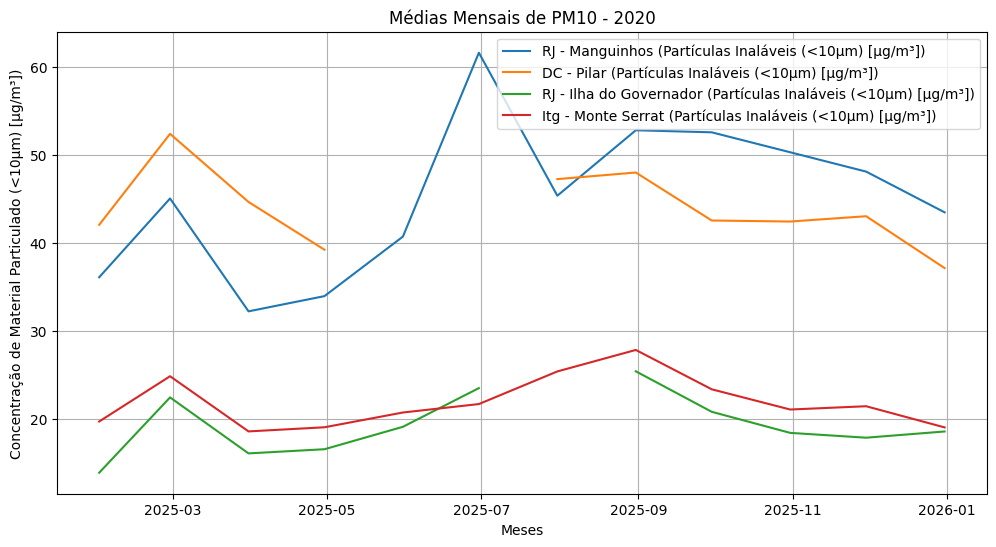

In [193]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

for coluna in colunas_pm10:
    plt.plot(media_mensal_pm_velidada.index, media_mensal_pm_velidada[coluna], label=coluna)

plt.title('Médias Mensais de PM10 - 2020')

plt.xlabel('Meses')

plt.ylabel('Concentração de Material Particulado (<10µm) [µg/m³])')

plt.grid(True)

plt.legend()

plt.show()




In [194]:
meses_validos = (media_mensal_pm_velidada.count())

media_anual_pm = (media_mensal_pm_velidada.mean())

resumo_anual_pm = pd.DataFrame()

resumo_anual_pm['Meses Válidos'] = meses_validos

resumo_anual_pm['Média Anual'] = media_anual_pm

display(resumo_anual_pm)

,Meses Válidos,Média Anual
RJ - Manguinhos (Partículas Inaláveis (<10µm) [µg/m³]),12,45.180405
DC - Pilar (Partículas Inaláveis (<10µm) [µg/m³]),10,43.865595
RJ - Ilha do Governador (Partículas Inaláveis (<10µm) [µg/m³]),11,19.347231
Itg - Monte Serrat (Partículas Inaláveis (<10µm) [µg/m³]),12,21.909177


In [195]:
pm10_anual = resumo_anual_pm.copy()

pm10_anual['PI-1 (40)'] = ((pm10_anual['Média Anual'] >= 40).astype(int))

pm10_anual['PI-2 (35)'] = ((pm10_anual['Média Anual'] >= 35) & (pm10_anual['Média Anual'] < 40)).astype(int)

pm10_anual['PI-3 (30)'] = ((pm10_anual['Média Anual'] >= 30) & (pm10_anual['Média Anual'] < 35)).astype(int)

pm10_anual['PI-4 (20)'] = ((pm10_anual['Média Anual'] >= 20) & (pm10_anual['Média Anual'] < 30)).astype(int)

pm10_anual['PF (15)'] = ((pm10_anual['Média Anual'] >= 15) & (pm10_anual['Média Anual'] < 20)).astype(int)

display(pm10_anual)



,Meses Válidos,Média Anual,PI-1 (40),PI-2 (35),PI-3 (30),PI-4 (20),PF (15)
RJ - Manguinhos (Partículas Inaláveis (<10µm) [µg/m³]),12,45.180405,1,0,0,0,0
DC - Pilar (Partículas Inaláveis (<10µm) [µg/m³]),10,43.865595,1,0,0,0,0
RJ - Ilha do Governador (Partículas Inaláveis (<10µm) [µg/m³]),11,19.347231,0,0,0,0,1
Itg - Monte Serrat (Partículas Inaláveis (<10µm) [µg/m³]),12,21.909177,0,0,0,1,0
